# 🎓 Projet Machine Learning n°2 — Spotify : décrypter la musique 🎧
**Module Machine Learning — B2 — Projet de groupe**

## 🎯 Contexte
Une start-up de la musique veut construire un outil qui **analyse automatiquement les morceaux** à partir de leurs caractéristiques audio, calculées par l'API Spotify.
Le jeu de données (TidyTuesday, issu de l'API Spotify) contient **~32 800 lignes** : des morceaux classés dans des playlists de **6 genres** (`edm`, `latin`, `pop`, `r&b`, `rap`, `rock`).

Vous devez répondre à deux questions :
1. **Régression** — Peut-on **prédire l'énergie** (`energy`) d'un morceau à partir de ses autres caractéristiques audio ? *(et, en bonus, sa popularité `track_popularity`)*
2. **Classification** — Peut-on **prédire le genre** (`playlist_genre`) d'un morceau à partir de ses caractéristiques audio ?

## 📚 Variables
| Variable | Description |
|---|---|
| `track_id`, `track_name`, `track_artist` | identifiant, titre, artiste |
| `track_popularity` | popularité (0 à 100) |
| `track_album_id`, `track_album_name`, `track_album_release_date` | album et date de sortie (texte, formats variables !) |
| `playlist_name`, `playlist_id`, `playlist_genre`, `playlist_subgenre` | playlist d'origine, **genre (cible classification)**, sous-genre |
| `danceability`, `energy`, `speechiness`, `acousticness`, `instrumentalness`, `liveness`, `valence` | indicateurs audio entre 0 et 1 — `energy` = **cible régression** |
| `loudness` | volume moyen (dB) |
| `tempo` | tempo (BPM) |
| `key`, `mode` | tonalité (0 à 11), mode (1 = majeur, 0 = mineur) |
| `duration_ms` | durée (millisecondes) |

---
## 🔍 Partie 1 — Analyse exploratoire des données (EDA)
1. **Structure** : dimensions, types, valeurs manquantes.
2. **Doublons** : un même morceau (`track_id`) peut apparaître dans **plusieurs playlists**. Combien de morceaux uniques ? Un morceau peut-il avoir plusieurs genres ? Décidez d'une stratégie (garder la première occurrence…) et justifiez-la.
3. **Changements de types et nouvelles variables** :
   - Extraire l'**année de sortie** de `track_album_release_date` (attention aux formats `2019`, `2019-06`, `2019-06-14`).
   - Convertir `duration_ms` en **minutes**.
   - Passer `playlist_genre` en `category`.
4. **Analyse univariée** : distribution de chaque caractéristique audio (histogrammes), de la popularité, de la durée, nombre de morceaux par genre.
5. **Analyse bivariée** :
   - Heatmap des corrélations entre caractéristiques audio : lesquelles sont les plus liées à `energy` ?
   - Boxplots des caractéristiques audio **par genre** : quelles variables distinguent le mieux les genres ?
   - Popularité moyenne par genre et selon l'année de sortie (courbe).
   - Nuage de points `loudness` vs `energy` coloré par genre.
6. **Top** : les 10 artistes les plus présents, les 10 morceaux les plus populaires.
7. **Synthèse** : rédigez **5 constats clés** sur la musique de ce catalogue.

---
## 📈 Partie 2 — Régression : prédire `energy`
- Variables explicatives : les **autres** caractéristiques audio (`loudness`, `acousticness`, `valence`, `danceability`, `tempo`…), sans `energy` bien sûr.

- Séparez `X` et `y`, puis découpez en **train / test** (80 / 20, `random_state=42`).
- Entraînez d'abord une **régression linéaire simple** (une seule variable, la plus corrélée à la cible) comme point de comparaison.
- Entraînez ensuite une **régression linéaire multiple** avec les variables numériques pertinentes, puis en ajoutant les variables catégorielles encodées (`pd.get_dummies(..., drop_first=True)`).
- Évaluez chaque modèle : **R²**, **MAE**, **RMSE** sur le train **et** sur le test. Y a-t-il de l'overfitting ?
- Affichez et **interprétez les coefficients** du meilleur modèle linéaire (avec `zip`).
- Tracez le graphique **valeurs réelles vs valeurs prédites** sur le jeu de test.
- *Bonus* : comparez avec un `RandomForestRegressor`.
- Rassemblez les résultats dans un **tableau comparatif** des modèles.

- *Bonus* : essayez de prédire `track_popularity` avec les mêmes méthodes. 📝 Que constatez-vous ? Pourquoi la popularité est-elle beaucoup plus difficile à prédire ?

📝 **Questions** : quelle variable explique le plus l'énergie ? Comment interpréter le coefficient de `loudness` ?

---
## 🧭 Partie 3 — Classification : prédire `playlist_genre` (6 classes)
- Variables explicatives : les caractéristiques audio, la durée et éventuellement l'année.

- Séparez `X` et `y`, découpez en **train / test** (80 / 20, `random_state=42`, `stratify=y`).
- Calculez l'accuracy d'un **modèle naïf** qui prédit toujours la classe majoritaire : c'est le score à battre.
- Entraînez une **régression logistique** (pensez à `max_iter` et à standardiser avec `StandardScaler` : `fit` sur le train uniquement).
- Entraînez un **KNN** en testant plusieurs valeurs de `k` ; repérez l'overfitting.
- Évaluez chaque modèle : **accuracy**, **précision**, **rappel**, **F1**, **matrice de confusion**, `classification_report`.
- Analysez les **probabilités** (`predict_proba`) sur quelques exemples.
- *Bonus* : comparez avec un `RandomForestClassifier` et affichez l'importance des variables.
- Rassemblez les résultats dans un **tableau comparatif** et justifiez le modèle retenu.

- C'est une classification **multi-classes** : lisez la matrice de confusion 6×6. Quels genres sont les **mieux reconnus** ? Lesquels sont **le plus confondus** entre eux ? Est-ce logique musicalement ?
- *Bonus* : créez une cible binaire « morceau populaire » (`track_popularity >= 60`) et entraînez un classifieur. Discutez les résultats.

📝 **Questions** : quel est le score d'un modèle qui répondrait au hasard parmi 6 genres ? Votre modèle fait-il beaucoup mieux ?

---
## 🖥️ Partie 4 — Restitution sous Streamlit

Le rendu final est une **application Streamlit** (`app.py`) qui présente votre travail à un public non technique.
L'application doit charger les données depuis le lien Internet (ou un modèle sauvegardé avec `joblib`) et contenir **au minimum** les pages suivantes (navigation via `st.sidebar`) :

### Page 1 — Accueil
- Contexte et objectif du projet, nom des membres du groupe
- Présentation du jeu de données : source, nombre de lignes / colonnes, aperçu (`st.dataframe`), dictionnaire des variables

### Page 2 — Exploration des données
- Au moins **5 visualisations** issues de votre analyse exploratoire, chacune accompagnée d'**un commentaire** (`st.markdown`)
- Au moins **un filtre interactif** (`st.selectbox`, `st.multiselect`, `st.slider`…) qui met à jour les graphiques
- Quelques indicateurs clés avec `st.metric`

### Page 3 — Modèle de régression
- **Informations sur le modèle** : algorithme(s) utilisé(s), variable cible, variables explicatives, préparation (encodage, standardisation…), paramètres, découpage train / test
- **Performances** : R², MAE (et RMSE) sur le train **et** le test, tableau comparatif des modèles testés
- Graphique **valeurs réelles vs prédites** et, pour la régression linéaire, les **coefficients**
- Un **formulaire de prédiction** (`st.number_input`, `st.selectbox`, `st.slider`) : l'utilisateur saisit des valeurs et obtient la prédiction
- Exemple : des curseurs (`st.slider`) pour chaque caractéristique audio → énergie prédite

### Page 4 — Modèle de classification
- **Informations sur le modèle** : algorithme(s), variable cible et ses classes, variables explicatives, préparation, paramètres (`max_iter`, `class_weight`, `n_neighbors`…)
- **Performances** : accuracy, précision, rappel, F1 (train et test), **matrice de confusion**, comparaison des modèles testés
- Justification de la **métrique principale** retenue
- Un **formulaire de prédiction** qui affiche la classe prédite **et les probabilités** (`predict_proba`)
- Exemple : des curseurs pour les caractéristiques audio → genre prédit + **graphique en barres des probabilités** des 6 genres ; un sélecteur de morceau existant pour comparer genre réel et genre prédit

### Page 5 — Conclusion
- Réponses à la problématique, limites des modèles, pistes d'amélioration

💡 Rappels utiles : `st.title`, `st.header`, `st.write`, `st.pyplot(fig)`, `st.columns`, `st.tabs`, `st.form`, `@st.cache_data` (chargement des données), `@st.cache_resource` (modèles).
Lancement : `streamlit run app.py`

---
## 📦 Livrables et évaluation

| Livrable | Contenu |
|---|---|
| Notebook | analyse exploratoire, préparation, modèles, conclusions (code commenté et exécuté) |
| `app.py` | application Streamlit fonctionnelle |
| `requirements.txt` | bibliothèques nécessaires (`streamlit`, `pandas`, `scikit-learn`, `matplotlib`, `seaborn`…) |
| Soutenance | 15 min de démonstration de l'application + 5 min de questions |

| Critère | Points |
|---|---|
| Analyse exploratoire (qualité, pertinence des graphiques et des commentaires) | 5 |
| Régression (préparation, modèles, évaluation, interprétation) | 4 |
| Classification (préparation, modèles, métriques adaptées, interprétation) | 4 |
| Application Streamlit (contenu, ergonomie, informations sur les modèles, prédictions) | 5 |
| Soutenance et qualité du code | 2 |
| **Total** | **20** |

In [2]:
# =========================================================
# Imports — manipulation et visualisation
# =========================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# =========================================================
# Imports — Machine Learning (scikit-learn)
# =========================================================
# Préparation des données
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Régression
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor          # bonus
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# Classification
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier         # bonus
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)

# Sauvegarde des modèles (pour les réutiliser dans Streamlit)
import joblib

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

# =========================================================
# 🔗 Jeu de données (lu directement depuis Internet)
# =========================================================
URL_SPOTIFY = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/master/data/2020/2020-01-21/spotify_songs.csv"
df = pd.read_csv(URL_SPOTIFY)
print(df.shape)
df.head()

(32833, 23)


,track_id,track_name,track_artist,track_popularity,track_album_id,track_album_name,track_album_release_date,playlist_name,playlist_id,playlist_genre,playlist_subgenre,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms
0,6f807x0ima9a1j3VPbc7VN,I Don't Care (with Justin Bieber) - Loud Luxur...,Ed Sheeran,66,2oCs0DGTsRO98Gh5ZSl2Cx,I Don't Care (with Justin Bieber) [Loud Luxury...,2019-06-14,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,dance pop,0.748,0.916,6,-2.634,1,0.0583,0.1020,0.000000,0.0653,0.518,122.036,194754
1,0r7CVbZTWZgbTCYdfa2P31,Memories - Dillon Francis Remix,Maroon 5,67,63rPSO264uRjW1X5E6cWv6,Memories (Dillon Francis Remix),2019-12-13,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,dance pop,0.726,0.815,11,-4.969,1,0.0373,0.0724,0.004210,0.3570,0.693,99.972,162600
2,1z1Hg7Vb0AhHDiEmnDE79l,All the Time - Don Diablo Remix,Zara Larsson,70,1HoSmj2eLcsrR0vE9gThr4,All the Time (Don Diablo Remix),2019-07-05,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,dance pop,0.675,0.931,1,-3.432,0,0.0742,0.0794,0.000023,0.1100,0.613,124.008,176616
3,75FpbthrwQmzHlBJLuGdC7,Call You Mine - Keanu Silva Remix,The Chainsmokers,60,1nqYsOef1yKKuGOVchbsk6,Call You Mine - The Remixes,2019-07-19,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,dance pop,0.718,0.930,7,-3.778,1,0.1020,0.0287,0.000009,0.2040,0.277,121.956,169093
4,1e8PAfcKUYoKkxPhrHqw4x,Someone You Loved - Future Humans Remix,Lewis Capaldi,69,7m7vv9wlQ4i0LFuJiE2zsQ,Someone You Loved (Future Humans Remix),2019-03-05,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,dance pop,0.650,0.833,1,-4.672,1,0.0359,0.0803,0.000000,0.0833,0.725,123.976,189052


## Partie 1 — Préparation et analyse exploratoire
Les morceaux présents dans plusieurs playlists peuvent avoir plusieurs genres. Pour éviter qu'un même `track_id` soit compté plusieurs fois et apparaisse dans plusieurs partitions, on conserve sa première occurrence et on documente le nombre de genres concernés.

Dimensions initiales : (32833, 23)


,type
track_id,object
track_name,object
track_artist,object
track_popularity,int64
track_album_id,object
track_album_name,object
track_album_release_date,object
playlist_name,object
playlist_id,object
playlist_genre,object


,valeurs_manquantes
track_name,5
track_artist,5
track_album_name,5
track_id,0
track_popularity,0
track_album_id,0
track_album_release_date,0
playlist_name,0
playlist_id,0
playlist_genre,0


Morceaux uniques : 28356
Lignes dupliquées par track_id : 4477
Morceaux associés à plusieurs genres : 1687
Dimensions après déduplication : (28356, 25)


,track_id,track_name,track_artist,track_popularity,track_album_id,track_album_name,track_album_release_date,playlist_name,playlist_id,playlist_genre,playlist_subgenre,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,release_year,duration_min
0,6f807x0ima9a1j3VPbc7VN,I Don't Care (with Justin Bieber) - Loud Luxur...,Ed Sheeran,66,2oCs0DGTsRO98Gh5ZSl2Cx,I Don't Care (with Justin Bieber) [Loud Luxury...,2019-06-14,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,dance pop,0.748,0.916,6,-2.634,1,0.0583,0.1020,0.000000,0.0653,0.518,122.036,194754,2019,3.245900
1,0r7CVbZTWZgbTCYdfa2P31,Memories - Dillon Francis Remix,Maroon 5,67,63rPSO264uRjW1X5E6cWv6,Memories (Dillon Francis Remix),2019-12-13,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,dance pop,0.726,0.815,11,-4.969,1,0.0373,0.0724,0.004210,0.3570,0.693,99.972,162600,2019,2.710000
2,1z1Hg7Vb0AhHDiEmnDE79l,All the Time - Don Diablo Remix,Zara Larsson,70,1HoSmj2eLcsrR0vE9gThr4,All the Time (Don Diablo Remix),2019-07-05,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,dance pop,0.675,0.931,1,-3.432,0,0.0742,0.0794,0.000023,0.1100,0.613,124.008,176616,2019,2.943600
3,75FpbthrwQmzHlBJLuGdC7,Call You Mine - Keanu Silva Remix,The Chainsmokers,60,1nqYsOef1yKKuGOVchbsk6,Call You Mine - The Remixes,2019-07-19,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,dance pop,0.718,0.930,7,-3.778,1,0.1020,0.0287,0.000009,0.2040,0.277,121.956,169093,2019,2.818217
4,1e8PAfcKUYoKkxPhrHqw4x,Someone You Loved - Future Humans Remix,Lewis Capaldi,69,7m7vv9wlQ4i0LFuJiE2zsQ,Someone You Loved (Future Humans Remix),2019-03-05,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,dance pop,0.650,0.833,1,-4.672,1,0.0359,0.0803,0.000000,0.0833,0.725,123.976,189052,2019,3.150867


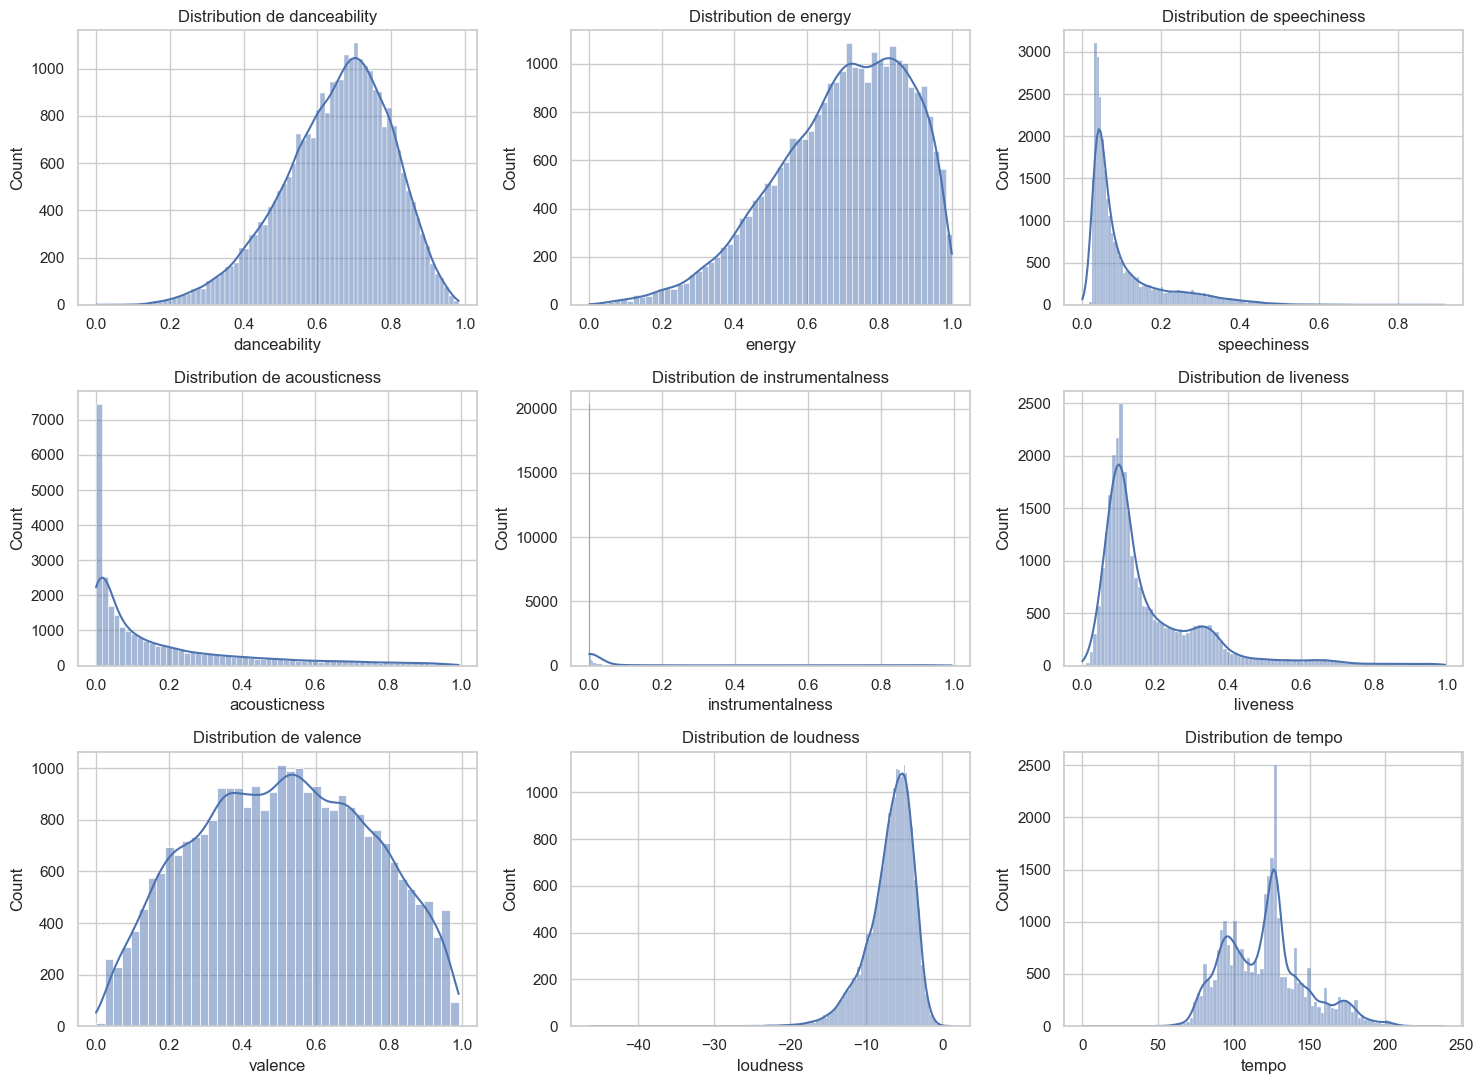

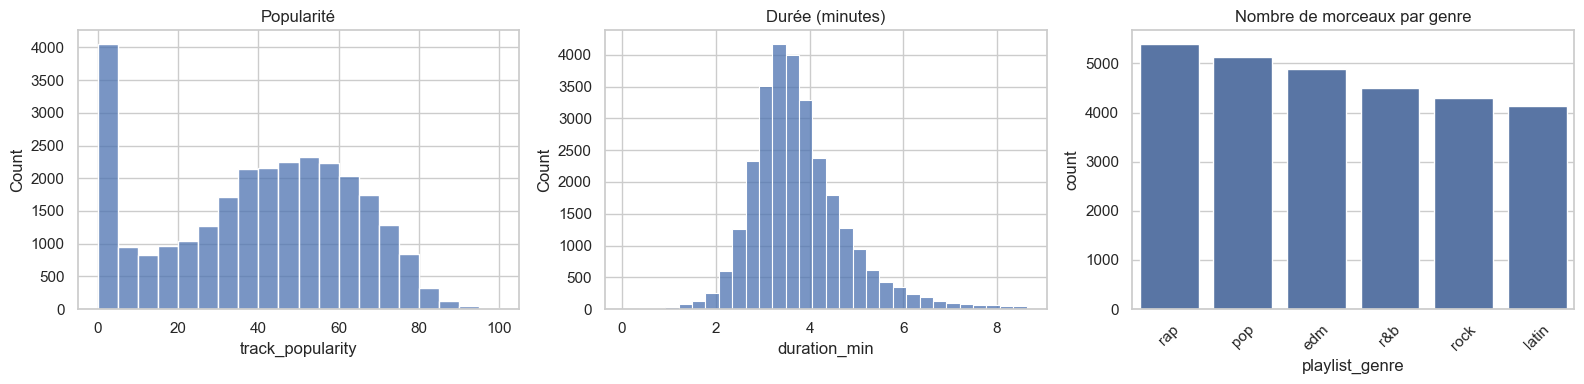

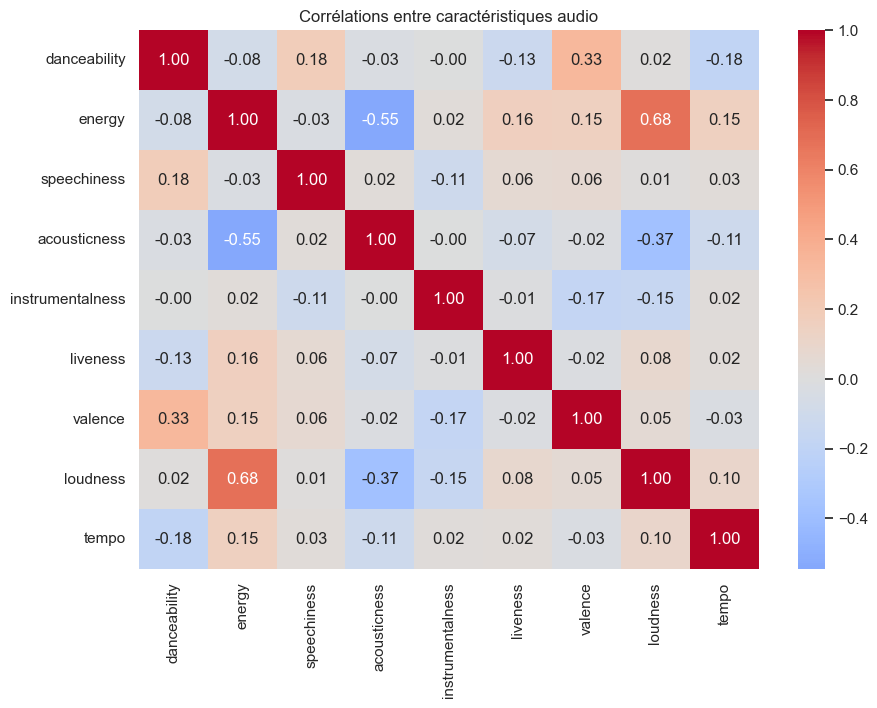

Corrélations avec energy :


,correlation
loudness,0.682138
acousticness,-0.545886
liveness,0.163709
tempo,0.151545
valence,0.149710
danceability,-0.081436
speechiness,-0.029008
instrumentalness,0.023818


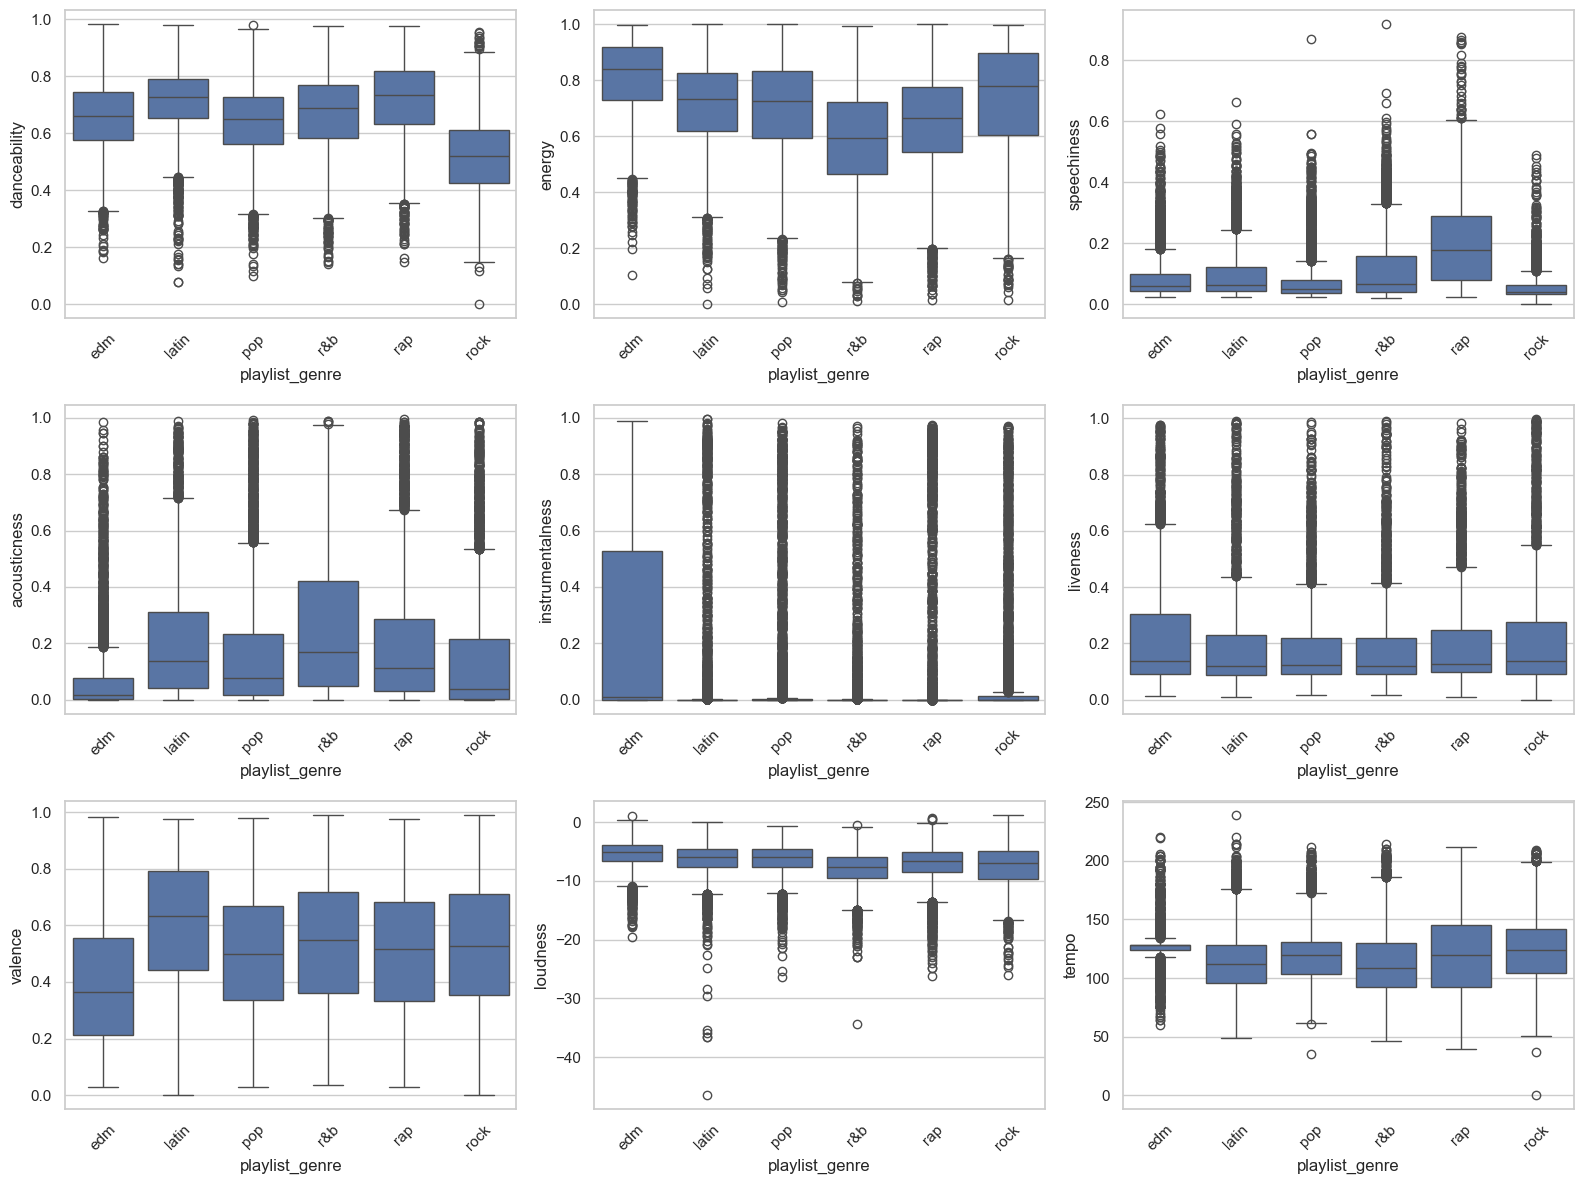

,popularite_moyenne
playlist_genre,
pop,45.905300
rap,41.822811
latin,41.439691
rock,39.694309
r&b,35.929396
edm,30.678286


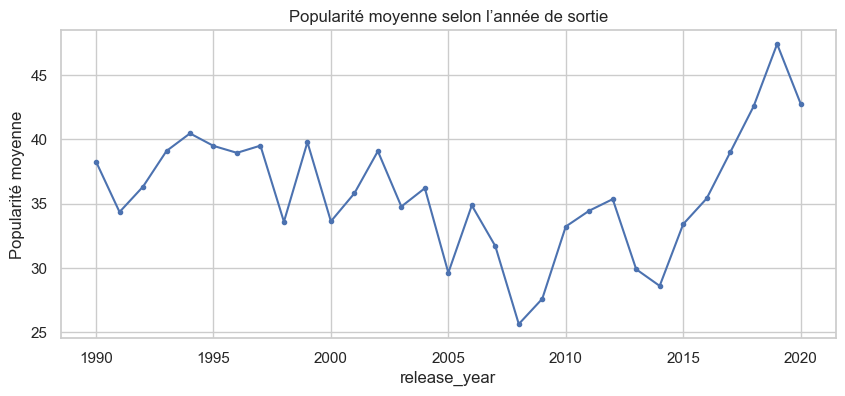

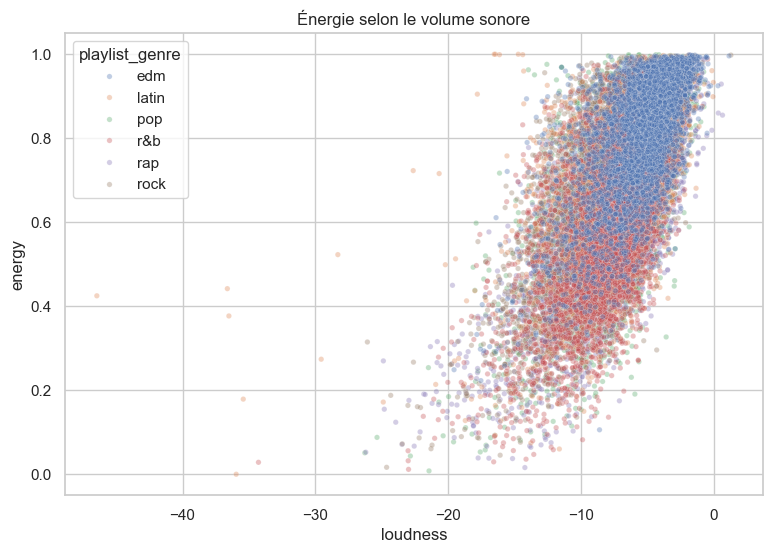

Top 10 artistes :


,nombre_morceaux
track_artist,
Queen,130
Martin Garrix,87
Don Omar,84
David Guetta,81
Hardwell,68
Drake,68
Dimitri Vegas & Like Mike,68
The Chainsmokers,66
Logic,65


Top 10 morceaux les plus populaires :


,track_name,track_artist,track_popularity,playlist_genre
1551,Dance Monkey,Tones and I,100,pop
20092,ROXANNE,Arizona Zervas,99,latin
687,Tusa,KAROL G,98,pop
711,Memories,Maroon 5,98,pop
716,Blinding Lights,The Weeknd,98,pop
1301,Circles,Post Malone,98,pop
5508,The Box,Roddy Ricch,98,rap
689,everything i wanted,Billie Eilish,97,pop
1302,Don't Start Now,Dua Lipa,97,pop
3155,Falling,Trevor Daniel,97,pop


In [3]:
print('Dimensions initiales :', df.shape)
display(df.dtypes.to_frame('type'))
display(df.isna().sum().sort_values(ascending=False).to_frame('valeurs_manquantes'))

genres_par_morceau = df.groupby('track_id')['playlist_genre'].nunique()
print('Morceaux uniques :', df['track_id'].nunique())
print('Lignes dupliquées par track_id :', int(df['track_id'].duplicated().sum()))
print('Morceaux associés à plusieurs genres :', int((genres_par_morceau > 1).sum()))

# Garder la première occurrence évite que le même morceau soit réparti entre train et test.
df = df.drop_duplicates(subset='track_id', keep='first').copy()
df['release_year'] = pd.to_numeric(
    df['track_album_release_date'].astype('string').str.extract(r'(\d{4})', expand=False),
    errors='coerce'
).astype('Int64')
df['duration_min'] = df['duration_ms'] / 60000
df['playlist_genre'] = df['playlist_genre'].astype('category')
print('Dimensions après déduplication :', df.shape)
display(df.head())

audio_cols = ['danceability', 'energy', 'speechiness', 'acousticness',
              'instrumentalness', 'liveness', 'valence', 'loudness', 'tempo']
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for col, ax in zip(audio_cols, axes.flat):
    sns.histplot(data=df, x=col, kde=True, ax=ax)
    ax.set_title(f'Distribution de {col}')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(data=df, x='track_popularity', bins=20, ax=axes[0])
axes[0].set_title('Popularité')
sns.histplot(data=df, x='duration_min', bins=30, ax=axes[1])
axes[1].set_title('Durée (minutes)')
sns.countplot(data=df, x='playlist_genre', order=df['playlist_genre'].value_counts().index, ax=axes[2])
axes[2].tick_params(axis='x', rotation=45)
axes[2].set_title('Nombre de morceaux par genre')
plt.tight_layout()
plt.show()

corr = df[audio_cols].corr(numeric_only=True)
plt.figure(figsize=(10, 7))
sns.heatmap(corr, annot=True, cmap='coolwarm', center=0, fmt='.2f')
plt.title('Corrélations entre caractéristiques audio')
plt.show()
print('Corrélations avec energy :')
display(corr['energy'].drop('energy').sort_values(key=abs, ascending=False).to_frame('correlation'))

fig, axes = plt.subplots(3, 3, figsize=(16, 12))
for col, ax in zip(audio_cols, axes.flat):
    sns.boxplot(data=df, x='playlist_genre', y=col, ax=ax)
    ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

display(df.groupby('playlist_genre', observed=True)['track_popularity'].mean().sort_values(ascending=False).to_frame('popularite_moyenne'))
popularite_annee = df.dropna(subset=['release_year']).groupby('release_year', observed=True)['track_popularity'].mean()
popularite_annee = popularite_annee.loc[(popularite_annee.index >= 1990) & (popularite_annee.index <= 2020)]
popularite_annee.plot(figsize=(10, 4), marker='.')
plt.title('Popularité moyenne selon l’année de sortie')
plt.ylabel('Popularité moyenne')
plt.show()

plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x='loudness', y='energy', hue='playlist_genre', alpha=0.35, s=15)
plt.title('Énergie selon le volume sonore')
plt.show()

print('Top 10 artistes :')
display(df['track_artist'].value_counts().head(10).to_frame('nombre_morceaux'))
print('Top 10 morceaux les plus populaires :')
display(df.nlargest(10, 'track_popularity')[['track_name', 'track_artist', 'track_popularity', 'playlist_genre']])

### Synthèse EDA — 5 constats
1. Le jeu initial compte 32 833 lignes, mais seulement 28 356 identifiants de morceaux ; les doublons viennent des apparitions dans plusieurs playlists.
2. Certains morceaux sont associés à plusieurs genres. On garde la première ligne par identifiant pour éviter qu'un même enregistrement soit dans plusieurs ensembles ; cette règle ne signifie pas que le genre retenu est un genre musical « vrai » unique.
3. Après déduplication, les six genres restent assez équilibrés, mais EDM est le plus représenté (environ 19 %). L'accuracy naïve de la classe majoritaire vaut donc environ 19 %.
4. `loudness` est fortement liée à `energy` (corrélation train ≈ 0,68) : les morceaux plus sonores sont généralement plus énergétiques. Les boxplots montrent également des différences entre genres, notamment sur l'acoustique et les caractéristiques rythmiques.
5. La popularité varie selon les genres et l'année, mais les caractéristiques audio seules ne décrivent pas la promotion, la notoriété de l'artiste ni le contexte de sortie.

## Partie 2 — Régression pour prédire `energy`
Les modèles partagent un même split 80/20. Le modèle linéaire simple utilise la caractéristique la plus corrélée à `energy`, choisie uniquement sur le train. Le modèle enrichi ajoute le genre et le sous-genre de playlist encodés.

Variable la plus corrélée avec energy (train) : loudness 0.6819897217185334


,modele,R2_train,R2_test,MAE_train,MAE_test,RMSE_train,RMSE_test
3,Forêt aléatoire,0.944885,0.719932,0.031683,0.074883,0.043019,0.097649
2,Linéaire + catégories,0.660232,0.670992,0.083548,0.083383,0.106812,0.105837
1,Linéaire numérique,0.624948,0.636290,0.088238,0.088460,0.112221,0.111279
0,Linéaire simple,0.465110,0.466055,0.106431,0.107613,0.134017,0.134829


Coefficients du meilleur modèle linéaire (triés par valeur absolue) :


,coefficient
acousticness,-0.223109
danceability,-0.158702
valence,0.155439
liveness,0.082216
instrumentalness,0.078806
speechiness,0.065114
playlist_subgenre_big room,0.054995
playlist_genre_r&b,-0.050354
playlist_subgenre_hard rock,0.049882
playlist_subgenre_neo soul,-0.042349


Coefficient de loudness : 0.032449845495884554


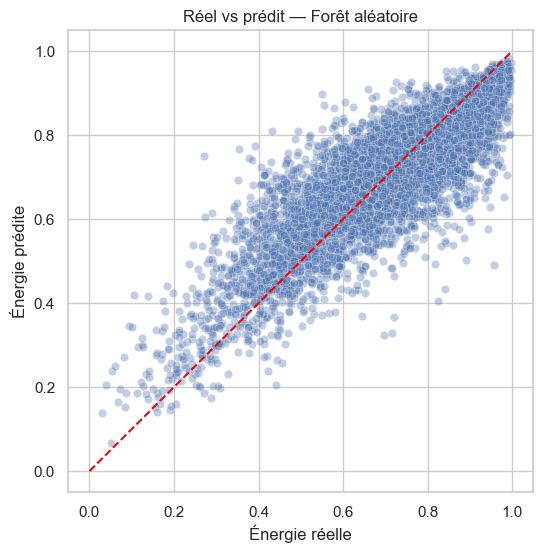

,modele,R2_train,R2_test,MAE_train,MAE_test,RMSE_train,RMSE_test
0,Popularité - forêt,0.805316,0.028858,8.335797,19.220533,10.452988,23.402323


In [4]:
from sklearn.base import clone

reg_num_cols = ['danceability', 'speechiness', 'acousticness', 'instrumentalness',
                'liveness', 'valence', 'loudness', 'tempo', 'duration_min', 'key', 'mode']
reg_cat_cols = ['playlist_genre', 'playlist_subgenre']
reg_data = df.dropna(subset=reg_num_cols + ['energy']).copy()
reg_indices_train, reg_indices_test = train_test_split(
    reg_data.index, test_size=0.2, random_state=42
)
y_reg_train = reg_data.loc[reg_indices_train, 'energy']
y_reg_test = reg_data.loc[reg_indices_test, 'energy']

corr_train = reg_data.loc[reg_indices_train, reg_num_cols + ['energy']].corr(numeric_only=True)['energy'].drop('energy')
simple_feature = corr_train.abs().idxmax()
print('Variable la plus corrélée avec energy (train) :', simple_feature, corr_train[simple_feature])

X_simple_train = reg_data.loc[reg_indices_train, [simple_feature]]
X_simple_test = reg_data.loc[reg_indices_test, [simple_feature]]
X_num_train = reg_data.loc[reg_indices_train, reg_num_cols]
X_num_test = reg_data.loc[reg_indices_test, reg_num_cols]
X_cat_train = pd.get_dummies(reg_data.loc[reg_indices_train, reg_num_cols + reg_cat_cols], columns=reg_cat_cols, drop_first=True, dtype=int)
X_cat_test = pd.get_dummies(reg_data.loc[reg_indices_test, reg_num_cols + reg_cat_cols], columns=reg_cat_cols, drop_first=True, dtype=int).reindex(columns=X_cat_train.columns, fill_value=0)

def evaluer_regression(nom, estimateur, Xtr, Xte, ytr, yte):
    estimateur.fit(Xtr, ytr)
    pred_train = estimateur.predict(Xtr)
    pred_test = estimateur.predict(Xte)
    return {
        'modele': nom,
        'R2_train': r2_score(ytr, pred_train),
        'R2_test': r2_score(yte, pred_test),
        'MAE_train': mean_absolute_error(ytr, pred_train),
        'MAE_test': mean_absolute_error(yte, pred_test),
        'RMSE_train': np.sqrt(mean_squared_error(ytr, pred_train)),
        'RMSE_test': np.sqrt(mean_squared_error(yte, pred_test)),
        'estimateur': estimateur,
        'pred_test': pred_test,
    }

reg_results = []
reg_results.append(evaluer_regression('Linéaire simple', LinearRegression(), X_simple_train, X_simple_test, y_reg_train, y_reg_test))
reg_results.append(evaluer_regression('Linéaire numérique', LinearRegression(), X_num_train, X_num_test, y_reg_train, y_reg_test))
reg_results.append(evaluer_regression('Linéaire + catégories', LinearRegression(), X_cat_train, X_cat_test, y_reg_train, y_reg_test))
reg_results.append(evaluer_regression('Forêt aléatoire', RandomForestRegressor(n_estimators=150, min_samples_leaf=2, random_state=42, n_jobs=-1), X_num_train, X_num_test, y_reg_train, y_reg_test))
regression_comparaison = pd.DataFrame([{k: v for k, v in r.items() if k not in ['estimateur', 'pred_test']} for r in reg_results])
display(regression_comparaison.sort_values('R2_test', ascending=False))

meilleur_reg = max(reg_results, key=lambda resultat: resultat['R2_test'])
meilleur_reg_lineaire = max(reg_results[:3], key=lambda resultat: resultat['R2_test'])
print('Coefficients du meilleur modèle linéaire (triés par valeur absolue) :')
colonnes_coef = X_cat_train.columns if meilleur_reg_lineaire['modele'] == 'Linéaire + catégories' else X_num_train.columns if meilleur_reg_lineaire['modele'] == 'Linéaire numérique' else X_simple_train.columns
coefs = pd.Series(meilleur_reg_lineaire['estimateur'].coef_, index=colonnes_coef)
display(coefs.reindex(coefs.abs().sort_values(ascending=False).index).to_frame('coefficient'))
print('Coefficient de loudness :', coefs.get('loudness', 'non utilisé'))

plt.figure(figsize=(6, 6))
sns.scatterplot(x=y_reg_test, y=meilleur_reg['pred_test'], alpha=0.35)
plt.plot([0, 1], [0, 1], color='red', linestyle='--')
plt.xlabel('Énergie réelle')
plt.ylabel('Énergie prédite')
plt.title(f"Réel vs prédit — {meilleur_reg['modele']}")
plt.show()

# Bonus : prédire la popularité avec les mêmes caractéristiques numériques.
pop_data = df.dropna(subset=reg_num_cols + ['track_popularity'])
pop_train_idx, pop_test_idx = train_test_split(pop_data.index, test_size=0.2, random_state=42)
pop_result = evaluer_regression(
    'Popularité - forêt',
    RandomForestRegressor(n_estimators=150, min_samples_leaf=2, random_state=42, n_jobs=-1),
    pop_data.loc[pop_train_idx, reg_num_cols], pop_data.loc[pop_test_idx, reg_num_cols],
    pop_data.loc[pop_train_idx, 'track_popularity'], pop_data.loc[pop_test_idx, 'track_popularity']
)
display(pd.DataFrame([{k: v for k, v in pop_result.items() if k not in ['estimateur', 'pred_test']}]))

### Réponses — régression
- Dans ce jeu, `loudness` est la variable la plus corrélée avec `energy` parmi les caractéristiques audio retenues (corrélation train observée ≈ 0,68).
- Le meilleur modèle linéaire test est celui avec les catégories encodées. Son coefficient de `loudness` est positif (environ 0,032) : à variables égales, +1 dB correspond à environ +0,032 d'énergie prédite. Cela ne prouve pas une causalité.
- La forêt aléatoire obtient un R² test d'environ 0,72, supérieur au meilleur modèle linéaire (environ 0,67), mais son R² train (environ 0,94) révèle du surapprentissage.
- La popularité est difficile à prédire à partir du son seul : elle dépend aussi de la notoriété, du marketing, de la date, de la playlist et des préférences des auditeurs.

## Partie 3 — Classification du genre musical
Les colonnes textuelles directement liées à l'étiquette (`playlist_genre`, `playlist_subgenre`, noms de playlist) sont exclues des variables explicatives : sinon la cible serait donnée au modèle. Les caractéristiques audio, la durée et l'année de sortie sont utilisées. Les données sont stratifiées pour conserver les proportions de genres.


Dimensions train : (22684, 13)
Dimensions test  : (5672, 13)
Genres : ['edm', 'latin', 'pop', 'r&b', 'rap', 'rock']
Classe majoritaire du train : rap
Accuracy naïve (classe majoritaire) : 0.190
Accuracy théorique du hasard uniforme : 1/6 = 0.167 (16.67%)
Meilleur modèle selon le F1 macro CV : Forêt aléatoire (0.589)
Meilleure valeur de k selon le F1 macro CV : KNN (k=31) (0.527)


,modele,f1_cv,accuracy_train,accuracy_test,precision_macro,rappel_macro,f1_macro
0,Forêt aléatoire,0.589,0.984,0.600,0.597,0.596,0.592
1,KNN (k=31),0.527,0.565,0.521,0.528,0.517,0.519
2,KNN (k=15),0.517,0.582,0.517,0.522,0.514,0.515
3,Régression logistique,0.490,0.499,0.488,0.484,0.486,0.483
4,KNN (k=5),0.486,0.640,0.488,0.497,0.488,0.488
5,KNN (k=1),0.454,0.995,0.446,0.448,0.445,0.446


,modele,k,f1_cv,accuracy_train,accuracy_test,precision_macro,rappel_macro,f1_macro
0,KNN (k=1),1,0.454,0.995,0.446,0.448,0.445,0.446
1,KNN (k=5),5,0.486,0.640,0.488,0.497,0.488,0.488
2,KNN (k=15),15,0.517,0.582,0.517,0.522,0.514,0.515
3,KNN (k=31),31,0.527,0.565,0.521,0.528,0.517,0.519



Régression logistique
F1 macro CV    : 0.490
Accuracy train : 0.499
Accuracy test  : 0.488
Précision macro : 0.484
Rappel macro    : 0.486
F1-score macro  : 0.483

Classification report :
              precision    recall  f1-score   support

         edm       0.54      0.61      0.57       976
       latin       0.39      0.32      0.35       827
         pop       0.37      0.40      0.38      1027
         r&b       0.46      0.37      0.41       901
         rap       0.54      0.55      0.54      1080
        rock       0.61      0.67      0.64       861

    accuracy                           0.49      5672
   macro avg       0.48      0.49      0.48      5672
weighted avg       0.48      0.49      0.48      5672



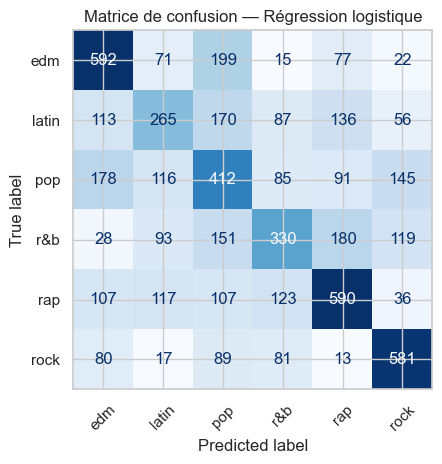


KNN (k=1)
F1 macro CV    : 0.454
Accuracy train : 0.995
Accuracy test  : 0.446
Précision macro : 0.448
Rappel macro    : 0.445
F1-score macro  : 0.446

Classification report :
              precision    recall  f1-score   support

         edm       0.54      0.56      0.55       976
       latin       0.33      0.34      0.34       827
         pop       0.32      0.35      0.33      1027
         r&b       0.38      0.36      0.37       901
         rap       0.52      0.47      0.49      1080
        rock       0.60      0.59      0.59       861

    accuracy                           0.45      5672
   macro avg       0.45      0.45      0.45      5672
weighted avg       0.45      0.45      0.45      5672



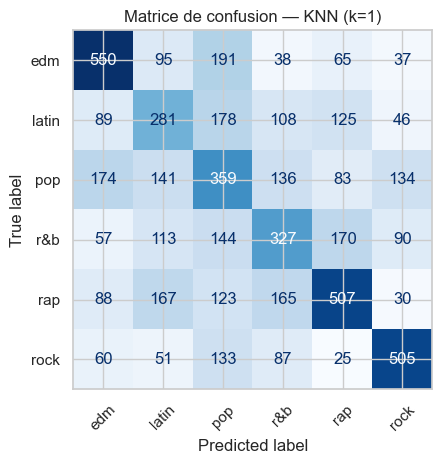


KNN (k=5)
F1 macro CV    : 0.486
Accuracy train : 0.640
Accuracy test  : 0.488
Précision macro : 0.497
Rappel macro    : 0.488
F1-score macro  : 0.488

Classification report :
              precision    recall  f1-score   support

         edm       0.52      0.69      0.59       976
       latin       0.38      0.41      0.40       827
         pop       0.35      0.38      0.36      1027
         r&b       0.42      0.36      0.39       901
         rap       0.63      0.48      0.55      1080
        rock       0.68      0.60      0.64       861

    accuracy                           0.49      5672
   macro avg       0.50      0.49      0.49      5672
weighted avg       0.50      0.49      0.49      5672



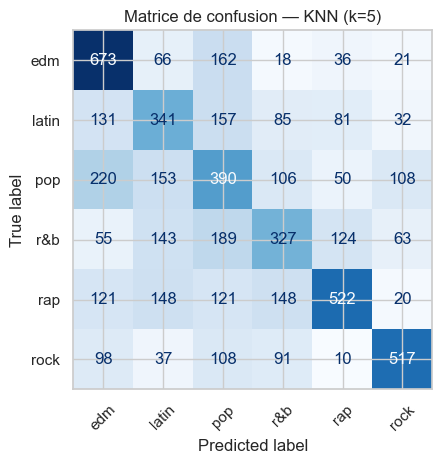


KNN (k=15)
F1 macro CV    : 0.517
Accuracy train : 0.582
Accuracy test  : 0.517
Précision macro : 0.522
Rappel macro    : 0.514
F1-score macro  : 0.515

Classification report :
              precision    recall  f1-score   support

         edm       0.56      0.69      0.62       976
       latin       0.42      0.38      0.40       827
         pop       0.36      0.43      0.39      1027
         r&b       0.47      0.39      0.42       901
         rap       0.62      0.56      0.59      1080
        rock       0.70      0.65      0.68       861

    accuracy                           0.52      5672
   macro avg       0.52      0.51      0.52      5672
weighted avg       0.52      0.52      0.52      5672



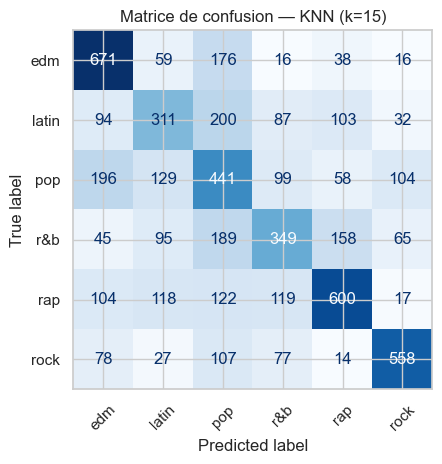


KNN (k=31)
F1 macro CV    : 0.527
Accuracy train : 0.565
Accuracy test  : 0.521
Précision macro : 0.528
Rappel macro    : 0.517
F1-score macro  : 0.519

Classification report :
              precision    recall  f1-score   support

         edm       0.58      0.69      0.63       976
       latin       0.46      0.36      0.40       827
         pop       0.35      0.44      0.39      1027
         r&b       0.48      0.39      0.43       901
         rap       0.61      0.58      0.59      1080
        rock       0.70      0.64      0.67       861

    accuracy                           0.52      5672
   macro avg       0.53      0.52      0.52      5672
weighted avg       0.53      0.52      0.52      5672



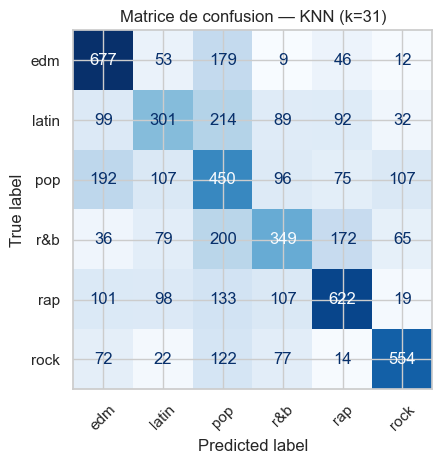


Forêt aléatoire
F1 macro CV    : 0.589
Accuracy train : 0.984
Accuracy test  : 0.600
Précision macro : 0.597
Rappel macro    : 0.596
F1-score macro  : 0.592

Classification report :
              precision    recall  f1-score   support

         edm       0.69      0.73      0.71       976
       latin       0.55      0.39      0.46       827
         pop       0.46      0.50      0.48      1027
         r&b       0.56      0.47      0.52       901
         rap       0.61      0.70      0.65      1080
        rock       0.70      0.79      0.74       861

    accuracy                           0.60      5672
   macro avg       0.60      0.60      0.59      5672
weighted avg       0.60      0.60      0.59      5672



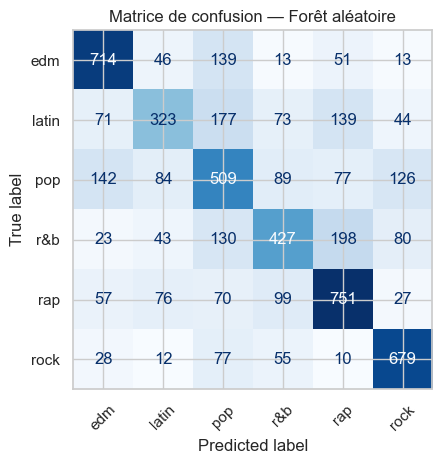

Modèle retenu : Forêt aléatoire
F1 macro CV   : 0.589
Accuracy test : 0.600
F1 macro test : 0.592
Écart accuracy train-test : 0.384


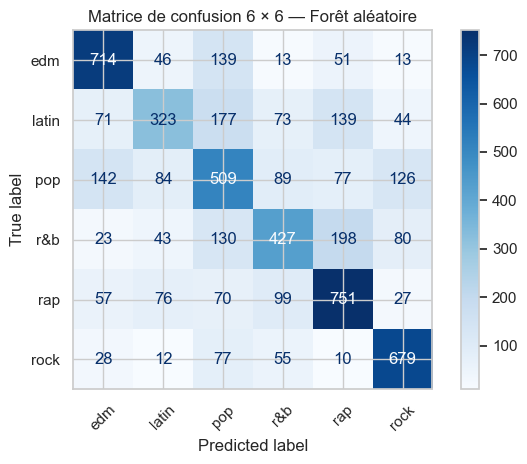

Genres les mieux reconnus :


,rappel
rock,78.9%
edm,73.2%
rap,69.5%
pop,49.6%
r&b,47.4%
latin,39.1%


Confusions les plus fréquentes :


,genre_reel,genre_predit,nombre
0,r&b,rap,198
1,latin,pop,177
2,pop,edm,142
3,edm,pop,139
4,latin,rap,139


Ces confusions sont plausibles : les genres de playlists peuvent partager des caractéristiques audio et leurs frontières musicales ne sont pas strictes.


,genre_reel,genre_predit,edm,latin,pop,r&b,rap,rock
32260,edm,edm,44.4%,18.9%,26.9%,1.1%,5.0%,3.8%
8602,rap,rap,3.8%,26.1%,4.5%,15.9%,48.4%,1.2%
9566,rap,rap,0.0%,3.1%,0.9%,18.3%,75.9%,1.8%
4586,pop,pop,10.8%,9.4%,72.2%,2.8%,3.1%,1.7%
8972,rap,r&b,2.4%,21.0%,4.4%,42.6%,25.6%,4.0%


La probabilité la plus élevée détermine le genre prédit. Des probabilités proches entre plusieurs genres signalent une prédiction plus incertaine.


,importance
tempo,0.116
release_year,0.112
speechiness,0.112
danceability,0.104
energy,0.088
acousticness,0.083
duration_min,0.076
valence,0.074
instrumentalness,0.071
loudness,0.067


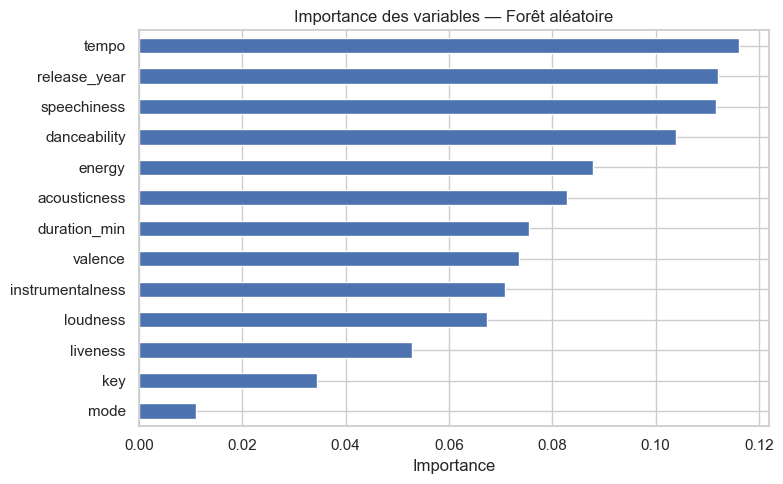

Bonus — morceaux populaires (seuil 60)


,accuracy_train,accuracy_test,precision_macro,rappel_macro,f1_macro
0,0.578,0.567,0.567,0.596,0.532


Part de morceaux populaires dans le test : 22.6%
Accuracy naïve (classe majoritaire) : 0.774
Précision de la classe populaire : 0.294
Rappel de la classe populaire : 0.649
                  precision    recall  f1-score   support

Moins populaires       0.84      0.54      0.66      4388
      Populaires       0.29      0.65      0.40      1284

        accuracy                           0.57      5672
       macro avg       0.57      0.60      0.53      5672
    weighted avg       0.72      0.57      0.60      5672



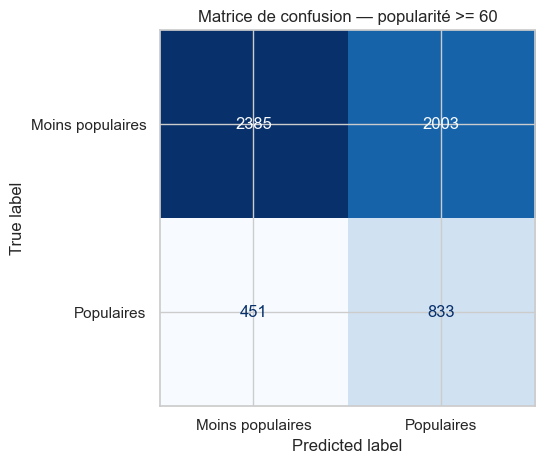

La popularité dépend aussi de facteurs absents des caractéristiques audio (notoriété, promotion, époque) : des performances modestes sont donc attendues.


['meilleur_modele_spotify.joblib']

In [5]:
# Imports nécessaires aux pipelines et à la validation croisée.
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score
import joblib

# ============================================================
# 1. PRÉPARATION DES DONNÉES POUR LA CLASSIFICATION DES GENRES
# ============================================================

# Caractéristiques audio, durée et année de sortie.
class_num_cols = [
    'danceability', 'energy', 'speechiness', 'acousticness',
    'instrumentalness', 'liveness', 'valence', 'loudness',
    'tempo', 'duration_min', 'key', 'mode', 'release_year'
]

# Les rares lignes incomplètes sont retirées uniquement pour les colonnes utiles.
class_data = df.dropna(subset=class_num_cols + ['playlist_genre']).copy()
X_class = class_data[class_num_cols]
y_class = class_data['playlist_genre'].astype(str)

# Split 80/20 reproductible et stratifié.
Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    X_class,
    y_class,
    test_size=0.2,
    random_state=42,
    stratify=y_class
)

print('Dimensions train :', Xc_train.shape)
print('Dimensions test  :', Xc_test.shape)
print('Genres :', sorted(y_class.unique()))


# ============================================================
# 2. MODÈLES NAÏFS : CLASSE MAJORITAIRE ET HASARD UNIFORME
# ============================================================

# La classe majoritaire est déterminée uniquement à partir du train,
# puis son accuracy est mesurée sur le jeu de test.
classe_majoritaire = yc_train.mode().iloc[0]
prediction_majoritaire = np.full(len(yc_test), classe_majoritaire)
accuracy_majoritaire = accuracy_score(yc_test, prediction_majoritaire)
accuracy_hasard = 1 / 6

print(f'Classe majoritaire du train : {classe_majoritaire}')
print(f'Accuracy naïve (classe majoritaire) : {accuracy_majoritaire:.3f}')
print(f'Accuracy théorique du hasard uniforme : 1/6 = {accuracy_hasard:.3f} '
      f'({accuracy_hasard:.2%})')


# ============================================================
# 3. RÉGRESSION LOGISTIQUE
# ============================================================

# Le scaler est dans le pipeline : fit() l'ajuste donc uniquement sur le train.
logistic_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=3000)
)


# ============================================================
# 4. K-NEAREST NEIGHBORS (KNN)
# ============================================================

# Chaque KNN possède son propre scaler, lui aussi ajusté uniquement sur le train.
valeurs_k = [1, 5, 15, 31]
knn_models = {
    f'KNN (k={k})': make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=k)
    )
    for k in valeurs_k
}


# ============================================================
# 5. RANDOM FOREST (BONUS)
# ============================================================

random_forest_model = RandomForestClassifier(
    n_estimators=150,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

# Tous les modèles sont réunis afin de leur appliquer la même évaluation.
classifiers = {
    'Régression logistique': logistic_model,
    **knn_models,
    'Forêt aléatoire': random_forest_model
}


# ============================================================
# 6. SÉLECTION SUR LE TRAIN PAR VALIDATION CROISÉE
# ============================================================

# Le F1 macro donne le même poids aux six genres. Le scaler des modèles
# concernés reste dans le pipeline et est donc réajusté dans chaque pli.
cv_classification = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=42
)
f1_cv_moyens = {}
for name, estimator in classifiers.items():
    scores_cv = cross_val_score(
        estimator, Xc_train, yc_train,
        scoring='f1_macro', cv=cv_classification, n_jobs=-1
    )
    f1_cv_moyens[name] = scores_cv.mean()

# Le choix est figé avant toute évaluation sur le jeu de test.
best_classifier_name = max(f1_cv_moyens, key=f1_cv_moyens.get)
best_knn_name = max(knn_models, key=lambda name: f1_cv_moyens[name])
print(f'Meilleur modèle selon le F1 macro CV : {best_classifier_name} '
      f'({f1_cv_moyens[best_classifier_name]:.3f})')
print(f'Meilleure valeur de k selon le F1 macro CV : {best_knn_name} '
      f'({f1_cv_moyens[best_knn_name]:.3f})')


# ============================================================
# 7. ENTRAÎNEMENT SUR TOUT LE TRAIN ET ÉVALUATION FINALE
# ============================================================

classification_results = []
predictions_class = {}
matrices_class = {}
labels_genres = np.sort(y_class.unique())

for name, estimator in classifiers.items():
    estimator.fit(Xc_train, yc_train)
    pred_train = estimator.predict(Xc_train)
    pred_test = estimator.predict(Xc_test)

    predictions_class[name] = pred_test
    matrices_class[name] = confusion_matrix(
        yc_test, pred_test, labels=labels_genres
    )
    classification_results.append({
        'modele': name,
        'f1_cv': f1_cv_moyens[name],
        'accuracy_train': accuracy_score(yc_train, pred_train),
        'accuracy_test': accuracy_score(yc_test, pred_test),
        'precision_macro': precision_score(
            yc_test, pred_test, average='macro', zero_division=0
        ),
        'rappel_macro': recall_score(
            yc_test, pred_test, average='macro', zero_division=0
        ),
        'f1_macro': f1_score(
            yc_test, pred_test, average='macro', zero_division=0
        )
    })

# Tableau comparatif trié selon le critère utilisé pour la sélection.
classification_results_df = (
    pd.DataFrame(classification_results)
    .sort_values('f1_cv', ascending=False)
    .reset_index(drop=True)
)
display(classification_results_df.style.format({
    colonne: '{:.3f}'
    for colonne in classification_results_df.columns
    if colonne != 'modele'
}))

# Tableau spécifique aux valeurs de k pour visualiser le surapprentissage.
knn_results = (
    pd.DataFrame(classification_results)
    .loc[lambda table: table['modele'].str.startswith('KNN')]
    .copy()
)
knn_results.insert(1, 'k', valeurs_k)
display(knn_results.reset_index(drop=True).style.format({
    colonne: '{:.3f}'
    for colonne in knn_results.columns
    if colonne not in ['modele', 'k']
}))

# Pour chaque modèle : métriques, matrice de confusion et rapport détaillé.
for name in classifiers:
    ligne = classification_results_df.loc[
        classification_results_df['modele'] == name
    ].iloc[0]
    print('\n' + '=' * 70)
    print(name)
    print(f"F1 macro CV    : {ligne['f1_cv']:.3f}")
    print(f"Accuracy train : {ligne['accuracy_train']:.3f}")
    print(f"Accuracy test  : {ligne['accuracy_test']:.3f}")
    print(f"Précision macro : {ligne['precision_macro']:.3f}")
    print(f"Rappel macro    : {ligne['rappel_macro']:.3f}")
    print(f"F1-score macro  : {ligne['f1_macro']:.3f}")
    print('\nClassification report :')
    print(classification_report(
        yc_test,
        predictions_class[name],
        labels=labels_genres,
        zero_division=0
    ))

    ConfusionMatrixDisplay(
        confusion_matrix=matrices_class[name],
        display_labels=labels_genres
    ).plot(xticks_rotation=45, cmap='Blues', colorbar=False)
    plt.title(f'Matrice de confusion — {name}')
    plt.tight_layout()
    plt.show()


# ============================================================
# 8. RÉSULTAT DU MODÈLE RETENU
# ============================================================

# Ce modèle a été retenu par validation croisée, sans consulter le test.
best_classifier = classifiers[best_classifier_name]
y_class_pred = predictions_class[best_classifier_name]

best_row = classification_results_df.loc[
    classification_results_df['modele'] == best_classifier_name
].iloc[0]
ecart_train_test = best_row['accuracy_train'] - best_row['accuracy_test']
print(f'Modèle retenu : {best_classifier_name}')
print(f"F1 macro CV   : {best_row['f1_cv']:.3f}")
print(f"Accuracy test : {best_row['accuracy_test']:.3f}")
print(f"F1 macro test : {best_row['f1_macro']:.3f}")
print(f'Écart accuracy train-test : {ecart_train_test:.3f}')


# ============================================================
# 9. ANALYSE DE LA MATRICE DE CONFUSION DU MODÈLE RETENU
# ============================================================

cm_best = matrices_class[best_classifier_name]
ConfusionMatrixDisplay(
    confusion_matrix=cm_best,
    display_labels=labels_genres
).plot(xticks_rotation=45, cmap='Blues')
plt.title(f'Matrice de confusion 6 × 6 — {best_classifier_name}')
plt.tight_layout()
plt.show()

# Le rappel par genre correspond à la diagonale divisée par le total de la ligne.
rappels_par_genre = pd.Series(
    np.diag(cm_best) / cm_best.sum(axis=1),
    index=labels_genres,
    name='rappel'
).sort_values(ascending=False)
print('Genres les mieux reconnus :')
display(rappels_par_genre.to_frame().style.format('{:.1%}'))

# Plus grandes cases hors diagonale = confusions les plus fréquentes.
confusions = []
for i, genre_reel in enumerate(labels_genres):
    for j, genre_predit in enumerate(labels_genres):
        if i != j:
            confusions.append({
                'genre_reel': genre_reel,
                'genre_predit': genre_predit,
                'nombre': cm_best[i, j]
            })
confusions_principales = (
    pd.DataFrame(confusions)
    .sort_values('nombre', ascending=False)
    .head(5)
    .reset_index(drop=True)
)
print('Confusions les plus fréquentes :')
display(confusions_principales)
print("Ces confusions sont plausibles : les genres de playlists peuvent partager "
      "des caractéristiques audio et leurs frontières musicales ne sont pas strictes.")


# ============================================================
# 10. PROBABILITÉS DE PRÉDICTION
# ============================================================

nb_exemples = 5
probabilites = best_classifier.predict_proba(Xc_test.iloc[:nb_exemples])
apercu_probas = pd.DataFrame(
    probabilites,
    columns=best_classifier.classes_,
    index=Xc_test.index[:nb_exemples]
)
apercu_probas.insert(0, 'genre_predit', y_class_pred[:nb_exemples])
apercu_probas.insert(0, 'genre_reel', yc_test.iloc[:nb_exemples].values)
display(apercu_probas.style.format({genre: '{:.1%}' for genre in best_classifier.classes_}))
print("La probabilité la plus élevée détermine le genre prédit. Des probabilités "
      "proches entre plusieurs genres signalent une prédiction plus incertaine.")


# ============================================================
# 11. IMPORTANCE DES VARIABLES DE LA RANDOM FOREST (BONUS)
# ============================================================

importances_foret = pd.Series(
    random_forest_model.feature_importances_,
    index=class_num_cols,
    name='importance'
).sort_values(ascending=False)
display(importances_foret.to_frame().style.format('{:.3f}'))

plt.figure(figsize=(8, 5))
importances_foret.sort_values().plot(kind='barh')
plt.title('Importance des variables — Forêt aléatoire')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()


# ============================================================
# 12. BONUS : PRÉDICTION BINAIRE DE LA POPULARITÉ
# ============================================================

# 1 = popularité supérieure ou égale à 60 ; 0 = popularité inférieure à 60.
popular_binary = (class_data['track_popularity'] >= 60).astype(int)
Xp_train, Xp_test, yp_train, yp_test = train_test_split(
    X_class,
    popular_binary,
    test_size=0.2,
    random_state=42,
    stratify=popular_binary
)

popular_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=3000, class_weight='balanced')
)
popular_model.fit(Xp_train, yp_train)
popular_pred_train = popular_model.predict(Xp_train)
popular_pred = popular_model.predict(Xp_test)

classe_pop_majoritaire = yp_train.mode().iloc[0]
popularite_accuracy_naive = accuracy_score(
    yp_test, np.full(len(yp_test), classe_pop_majoritaire)
)
popularite_rapport = classification_report(
    yp_test, popular_pred, output_dict=True, zero_division=0
)

popularite_resultats = pd.DataFrame([{
    'accuracy_train': accuracy_score(yp_train, popular_pred_train),
    'accuracy_test': accuracy_score(yp_test, popular_pred),
    'precision_macro': precision_score(
        yp_test, popular_pred, average='macro', zero_division=0
    ),
    'rappel_macro': recall_score(
        yp_test, popular_pred, average='macro', zero_division=0
    ),
    'f1_macro': f1_score(
        yp_test, popular_pred, average='macro', zero_division=0
    )
}])

print('Bonus — morceaux populaires (seuil 60)')
display(popularite_resultats.style.format('{:.3f}'))
print(f'Part de morceaux populaires dans le test : {yp_test.mean():.1%}')
print(f'Accuracy naïve (classe majoritaire) : {popularite_accuracy_naive:.3f}')
print(f"Précision de la classe populaire : {popularite_rapport['1']['precision']:.3f}")
print(f"Rappel de la classe populaire : {popularite_rapport['1']['recall']:.3f}")
print(classification_report(
    yp_test,
    popular_pred,
    target_names=['Moins populaires', 'Populaires'],
    zero_division=0
))
ConfusionMatrixDisplay.from_predictions(
    yp_test,
    popular_pred,
    display_labels=['Moins populaires', 'Populaires'],
    cmap='Blues',
    colorbar=False
)
plt.title('Matrice de confusion — popularité >= 60')
plt.tight_layout()
plt.show()

print("La popularité dépend aussi de facteurs absents des caractéristiques audio "
      "(notoriété, promotion, époque) : des performances modestes sont donc attendues.")
joblib.dump(best_classifier, "meilleur_modele_spotify.joblib")

### Conclusion — classification
- La sélection est réalisée uniquement sur le train, par validation croisée stratifiée à cinq plis et selon le **F1 macro moyen**. La **forêt aléatoire** est ainsi retenue avec un F1 macro CV de **58,9 %**, avant toute consultation du test. Une fois réentraînée sur tout le train, elle obtient **60,0 % d'accuracy test** et **59,2 % de F1 macro test**.
- Cette performance dépasse nettement le hasard uniforme parmi six genres (**16,67 %**) et le modèle naïf prédisant toujours la classe majoritaire, `rap` (**19,0 %**). Le test sert ici uniquement à l'évaluation finale et ne modifie pas le choix du modèle.
- La forêt reste toutefois en **surapprentissage** : son accuracy est de **98,4 % sur le train**, contre **60,0 % sur le test**. Pour le KNN, `k=1` mémorise presque le train (99,5 %) mais ne réalise que 44,6 % sur le test. Lorsque `k` augmente, la décision est lissée et l'écart train-test diminue ; `k=31` est le meilleur KNN selon la validation croisée (F1 macro CV **52,7 %**) et obtient 52,1 % d'accuracy test.
- D'après la matrice de confusion du modèle retenu, les genres les mieux reconnus sont **rock** (rappel 78,9 %), **EDM** (73,2 %) et **rap** (69,5 %). `latin` est le moins bien reconnu (39,1 %).
- Les confusions les plus fréquentes sont **R&B prédit rap** (198 morceaux), **latin prédit pop** (177), puis **pop prédit EDM** (142). Elles sont cohérentes musicalement : R&B et rap partagent souvent des rythmes et des productions, tandis que latin, pop et EDM peuvent se mélanger dans des titres dansants et hybrides. Les étiquettes correspondent en outre à des playlists, dont les frontières ne sont pas strictes.
- Les probabilités permettent de repérer l'incertitude : dans les cinq exemples affichés, quatre prédictions sont correctes. Pour l'exemple `rap` classé `r&b`, les probabilités de `r&b` (42,6 %) et de `rap` (25,6 %) restent relativement proches.
- L'importance des variables de la forêt confirme l'observation précédente : **`tempo` (11,6 %), `release_year` (11,2 %), `speechiness` (11,2 %) et `danceability` (10,4 %)** sont toujours les quatre caractéristiques les plus importantes. Ces importances indiquent leur utilité pour les décisions de la forêt, sans prouver une relation causale.
- Pour le bonus popularité, les morceaux populaires sont minoritaires (**22,6 %** du test). La régression logistique équilibrée obtient **56,7 % d'accuracy test** et **53,2 % de F1 macro**, donc une accuracy bien inférieure aux **77,4 %** du modèle naïf majoritaire. `class_weight="balanced"` accorde davantage de poids à la classe populaire : son rappel atteint **64,9 %**, mais sa précision n'est que de **29,4 %**, ce qui traduit de nombreux faux positifs. L'accuracy seule est donc insuffisante ; le rappel, la précision, le F1 macro et la matrice de confusion sont nécessaires pour comprendre ce compromis.


## Conclusion générale
Les attributs audio contiennent un signal utile pour estimer l'énergie et reconnaître le genre, mais ne résument ni le contexte de diffusion ni la popularité. Le jeu étant observationnel, les relations relevées sont associatives et ne prouvent pas de causalité. La déduplication par morceau, les partitions fixes et la comparaison train/test rendent l'évaluation plus fiable. L'application Streamlit associée permet d'explorer les graphiques et de tester les modèles de façon interactive.